# Real vs Fake Face Image Classification

>**Download Dataset from Kaggle:**


In [ ]:
!pip install kagglehub

import kagglehub
path = kagglehub.dataset_download("sachchitkunichetty/rvf10k")
print("Path to dataset files:", path)

import os
DATASET_PATH = path
TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
VALID_DIR = os.path.join(DATASET_PATH, 'valid')

print(os.listdir(DATASET_PATH))

100%|██████████| 273M/273M [00:02<00:00, 119MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sachchitkunichetty/rvf10k/versions/2
['valid.csv', 'train.csv', 'rvf10k']


In [ ]:
#   Google Drive
from google.colab import drive
drive.mount('/content/drive')

import shutil
shutil.copytree(
    '/root/.cache/kagglehub/datasets/sachchitkunichetty/rvf10k/versions/2/rvf10k',
    '/content/drive/MyDrive/rvf10k'  #Drive
)
print("Copied dataset to Google Drive successfully")

Mounted at /content/drive
Copied dataset to Google Drive successfully


In [ ]:
# Mount Google Drive to access saved dataset
from google.colab import drive
drive.mount('/content/drive')

import os
# Define paths to dataset directories
DATASET_PATH = '/content/drive/MyDrive/rvf10k'   # Root dataset folder
TRAIN_DIR    = os.path.join(DATASET_PATH, 'train') # Training images
VALID_DIR    = os.path.join(DATASET_PATH, 'valid') # Validation images

# Verify dataset structure
print("Train folders:", os.listdir(TRAIN_DIR))
print("Valid folders:", os.listdir(VALID_DIR))

Mounted at /content/drive
Train folders: ['fake', 'real']
Valid folders: ['real', 'fake']


In [ ]:
# Copy dataset from Drive to local Colab storage
# Much faster than reading directly from Drive
import shutil

print('Copying dataset... please wait ⏳')

shutil.copytree(
    '/content/drive/MyDrive/rvf10k',
    '/content/rvf10k'
)

TRAIN_DIR = '/content/rvf10k/train'
VALID_DIR = '/content/rvf10k/valid'

print('✅ Done!')
print('Train folders:', os.listdir(TRAIN_DIR))
print('Valid folders:', os.listdir(VALID_DIR))

Copying dataset... please wait ⏳
✅ Done!
Train folders: ['real', 'fake']
Valid folders: ['real', 'fake']


> **Import All Required Libraries**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')  # Suppress unnecessary warnings
# TensorFlow & Keras — for building and training models

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50, EfficientNetB0
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Scikit-learn — for evaluation metrics and cross-validation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)
from sklearn.model_selection import KFold

# Set random seeds for reproducibility
# Ensures same results every time we run

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Confirm TensorFlow version and GPU availability
print(f'TensorFlow version : {tf.__version__}')
print(f'GPU available      : {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow version : 2.20.0
GPU available      : True


In [ ]:
!pip install keras-tuner -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 9.8 MB/s eta 0:00:00




> **Exploratory Data Analysis (EDA)**



In [ ]:
#Count Images per Class

# Count images in training set
train_real = len(os.listdir(os.path.join(TRAIN_DIR, 'real')))
train_fake = len(os.listdir(os.path.join(TRAIN_DIR, 'fake')))

# Count images in validation set
valid_real = len(os.listdir(os.path.join(VALID_DIR, 'real')))
valid_fake = len(os.listdir(os.path.join(VALID_DIR, 'fake')))

# Print results
print('===== Dataset Distribution =====')
print(f'Train — Real : {train_real} images')
print(f'Train — Fake : {train_fake} images')
print(f'Train — Total: {train_real + train_fake} images')
print()
print(f'Valid — Real : {valid_real} images')
print(f'Valid — Fake : {valid_fake} images')
print(f'Valid — Total: {valid_real + valid_fake} images')

===== Dataset Distribution =====
Train — Real : 3500 images
Train — Fake : 3500 images
Train — Total: 7000 images

Valid — Real : 1500 images
Valid — Fake : 1500 images
Valid — Total: 3000 images


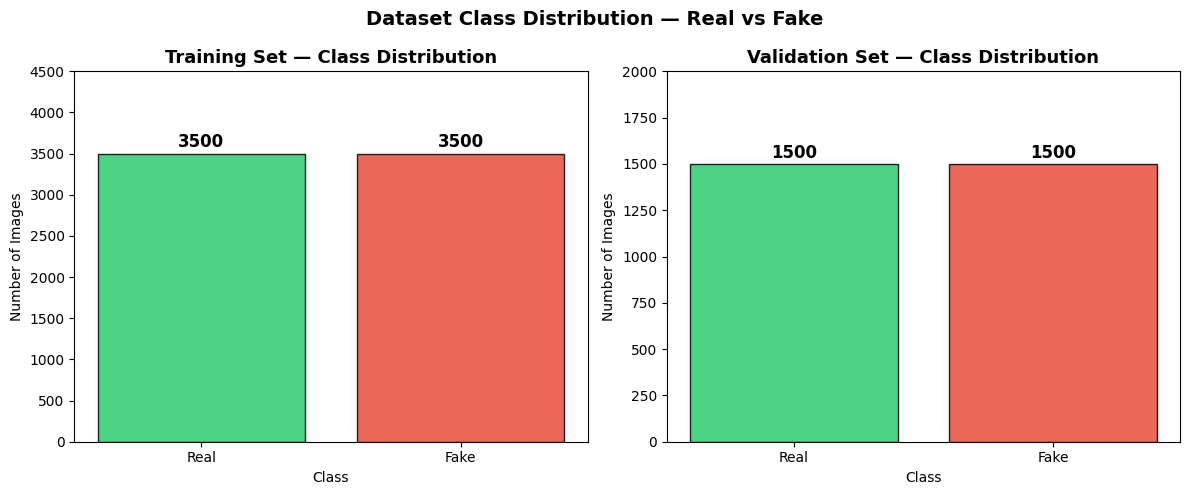

In [ ]:
# Visualize Class Distribution

import matplotlib.pyplot as plt

# Data for plotting
classes      = ['Real', 'Fake']
train_counts = [train_real, train_fake]
valid_counts  = [valid_real, valid_fake]
colors        = ['#2ecc71', '#e74c3c']  # Green=Real, Red=Fake

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Train set bar chart ---
bars = axes[0].bar(classes, train_counts,
                   color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('Training Set — Class Distribution',
                   fontsize=13, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Images')
axes[0].set_ylim(0, 4500)
# Show count on top of each bar
for bar, val in zip(bars, train_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 80,
                 str(val), ha='center', fontweight='bold', fontsize=12)

# --- Validation set bar chart ---
bars = axes[1].bar(classes, valid_counts,
                   color=colors, edgecolor='black', alpha=0.85)
axes[1].set_title('Validation Set — Class Distribution',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of Images')
axes[1].set_ylim(0, 2000)
# Show count on top of each bar
for bar, val in zip(bars, valid_counts):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 30,
                 str(val), ha='center', fontweight='bold', fontsize=12)

plt.suptitle('Dataset Class Distribution — Real vs Fake',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The dataset is perfectly balanced with a 50/50 split between Real and Fake classes. The training set contains 7,000 images (3,500 Real / 3,500 Fake), and the validation set contains 3,000 images (1,500 Real / 1,500 Fake). This equal distribution ensures the model will not be biased toward either class during training, making Accuracy a reliable evaluation metric

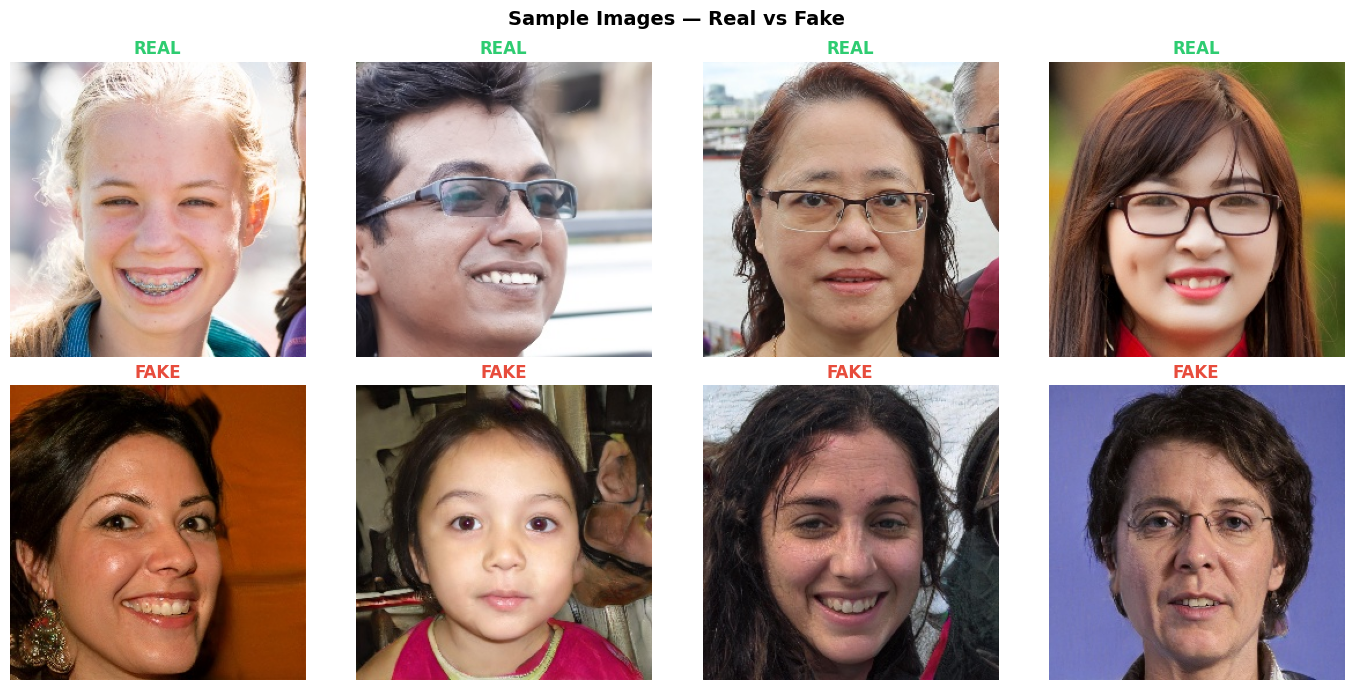

In [ ]:
# Visualize Sample Images — Real vs Fake

import matplotlib.image as mpimg
import random

def show_sample_images(directory, n_per_class=4):
    #Display random sample images from each class.

    fig, axes = plt.subplots(2, n_per_class, figsize=(14, 7))

    for i, cls in enumerate(['real', 'fake']):
        cls_path = os.path.join(directory, cls)
        sample_imgs = random.sample(os.listdir(cls_path), n_per_class)

        for j, img_name in enumerate(sample_imgs):
            img = mpimg.imread(os.path.join(cls_path, img_name))
            axes[i][j].imshow(img)
            axes[i][j].axis('off')
            # Show label on every image
            axes[i][j].set_title(
                'REAL' if cls == 'real' else 'FAKE',
                fontsize=12,
                fontweight='bold',
                color='#2ecc71' if cls == 'real' else '#e74c3c'
            )

    plt.suptitle('Sample Images — Real vs Fake',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR)



> **Preprocessing - Data Augmentation**e



Preprocessing & Data Augmentation:

The original dataset contains 3500 images per class (real/fake). Images were resized to 128×128 and normalized by rescaling pixel values from [0, 255] to [0, 1].
To improve generalization, augmentation was applied to the training set only using: horizontal flip, zoom, rotation, width/height shift, and brightness adjustment. Each image produced 2 augmented copies.

Final dataset:

Train: 21,000 images

Valid: 3,000 images

In [ ]:
# Preprocessing - Data Augmentation

import os
import numpy as np
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator, load_img, img_to_array, save_img
)

# Augmentation settings
AUGMENT_PER_IMAGE = 2  # Each image  2 extra copies
AUG_TRAIN_DIR     = '/content/augmented_data/train'

augmentor = ImageDataGenerator(
    horizontal_flip=True,
    zoom_range=0.15,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest'
)
# Define Global Hyperparameters
IMG_SIZE   = (128, 128)
BATCH_SIZE = 32
EPOCHS     = 30
SEED       = 42

def augment_and_save(src_dir, dst_dir, n_augments=3):

    #Load original images, augment them, and save to new directory.
    #Final dataset = original + augmented images.
    os.makedirs(dst_dir, exist_ok=True)

    for cls in ['real', 'fake']:
        src_cls = os.path.join(src_dir, cls)
        dst_cls = os.path.join(dst_dir, cls)
        os.makedirs(dst_cls, exist_ok=True)

        images = os.listdir(src_cls)
        print(f'Processing {cls}: {len(images)} original images...')

        for fname in images:
            # Save original image
            src_path = os.path.join(src_cls, fname)
            dst_path = os.path.join(dst_cls, fname)
            img = load_img(src_path, target_size=IMG_SIZE)
            save_img(dst_path, img_to_array(img))

            # Generate and save augmented copies
            img_array = img_to_array(img)
            img_array = np.expand_dims(img_array, axis=0)

            aug_iter = augmentor.flow(
                img_array, batch_size=1, seed=SEED
            )
            for i in range(n_augments):
                aug_img = next(aug_iter)[0]
                aug_name = f'aug{i}_{fname}'
                save_img(os.path.join(dst_cls, aug_name), aug_img)

        # Count final images
        total = len(os.listdir(dst_cls))
        print(f'  {cls}: {len(images)} → {total} images')

# Run augmentation
augment_and_save(TRAIN_DIR, AUG_TRAIN_DIR, n_augments=AUGMENT_PER_IMAGE)
# Update paths to use augmented dataset
AUG_TRAIN_DIR_REAL = os.path.join(AUG_TRAIN_DIR, 'real')
AUG_TRAIN_DIR_FAKE = os.path.join(AUG_TRAIN_DIR, 'fake')

print(f'\nAugmented dataset:')
print(f'  real: {len(os.listdir(AUG_TRAIN_DIR_REAL))} images')
print(f'  fake: {len(os.listdir(AUG_TRAIN_DIR_FAKE))} images')

# Create new generators from augmented dataset
#  rescale
train_datagen = ImageDataGenerator(rescale=1./255)
valid_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    AUG_TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

valid_gen = valid_datagen.flow_from_directory(
    VALID_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f'\nClass indices : {train_gen.class_indices}')
print(f'Train batches : {len(train_gen)}')
print(f'Valid batches : {len(valid_gen)}')

Processing real: 3500 original images...
  real: 3500 → 10500 images
Processing fake: 3500 original images...
  fake: 3500 → 10500 images

Augmented dataset:
  real: 10500 images
  fake: 10500 images
Found 21000 images belonging to 2 classes.
Found 3000 images belonging to 2 classes.

Class indices : {'fake': 0, 'real': 1}
Train batches : 657
Valid batches : 94


In [ ]:
import shutil

#Saving augmented dataset to Drive
shutil.copytree(
    '/content/augmented_data',
    '/content/drive/MyDrive/augmented_data'
)
print('Saved!')

Saved!


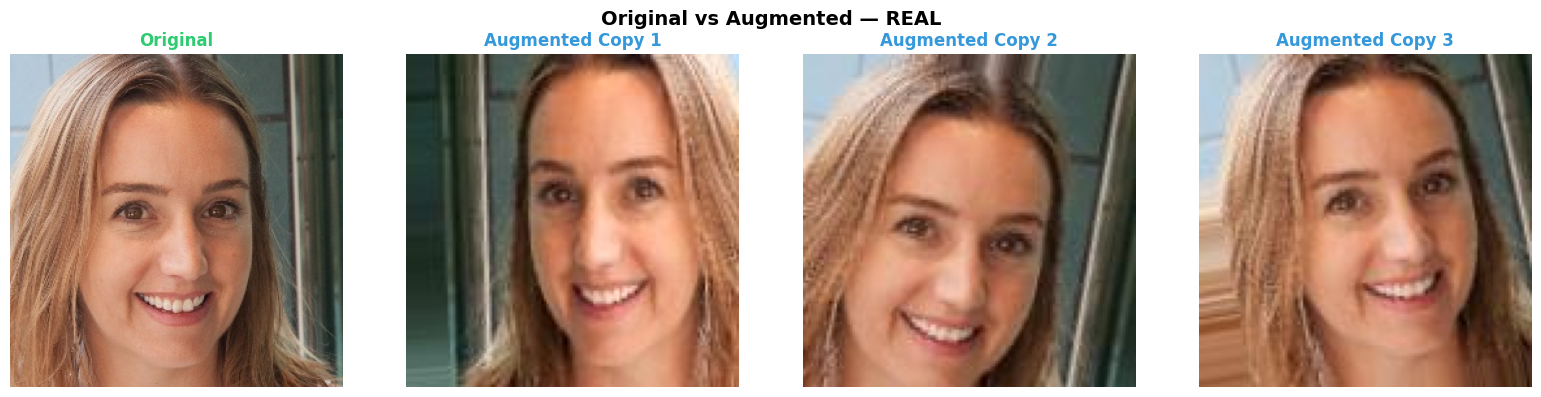

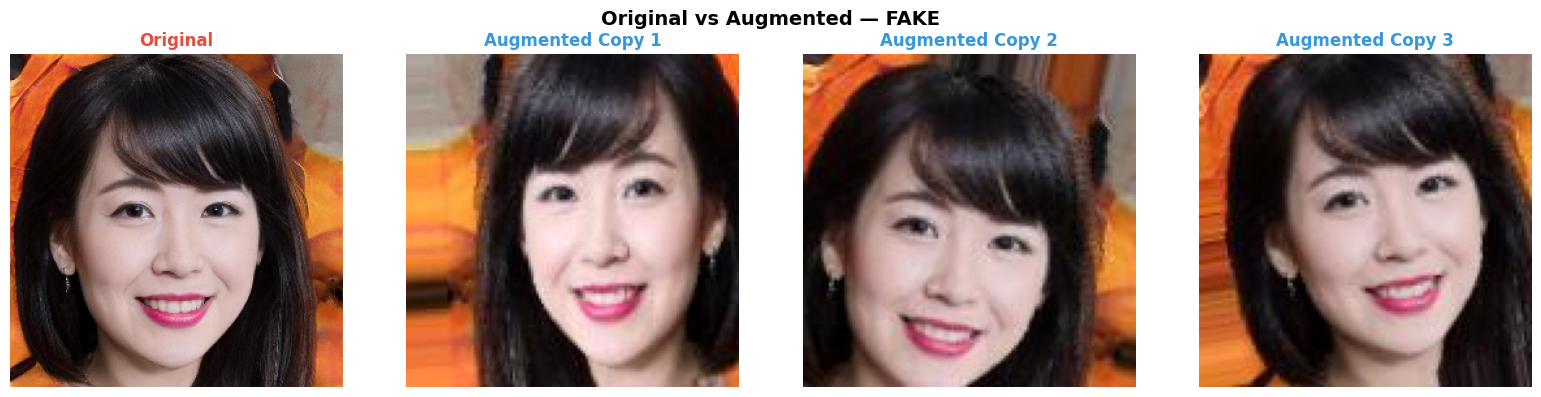

In [ ]:
# Visualize Augmented Images

import matplotlib.image as mpimg
import os

def show_original_with_augmented(cls='real'):

    #Show one original image alongside its augmented copies.
    src_dir = os.path.join(TRAIN_DIR, cls)
    aug_dir = os.path.join(AUG_TRAIN_DIR, cls)

    # Pick first original image
    original_name = os.listdir(src_dir)[0]
    base_name     = original_name

    # Find its augmented copies
    aug_names = [f'aug{i}_{base_name}' for i in range(3)]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # Plot original
    orig_img = mpimg.imread(os.path.join(src_dir, original_name))
    axes[0].imshow(orig_img)
    axes[0].set_title('Original', fontweight='bold',
                      color='#2ecc71' if cls == 'real' else '#e74c3c',
                      fontsize=12)
    axes[0].axis('off')

    # Plot  augmented copies
    for i, aug_name in enumerate(aug_names):
        aug_path = os.path.join(aug_dir, aug_name)
        aug_img  = mpimg.imread(aug_path)
        axes[i+1].imshow(aug_img)
        axes[i+1].set_title(f'Augmented Copy {i+1}',
                             fontweight='bold',
                             color='#3498db', fontsize=12)
        axes[i+1].axis('off')

    plt.suptitle(f'Original vs Augmented — {cls.upper()}',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Show for real class
show_original_with_augmented(cls='real')

# Show for fake class
show_original_with_augmented(cls='fake')

In [ ]:
# Mount Google Drive to access saved dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

src = '/content/drive/MyDrive/augmented_data/train'
dst = '/content/train_data'

shutil.copytree(src, dst, dirs_exist_ok=True)

print("Data copied to Colab!")

Data copied to Colab!


In [ ]:
import shutil

src = '/content/drive/MyDrive/rvf10k/valid'
dst = '/content/valid'

shutil.copytree(src, dst, dirs_exist_ok=True)

print("Data copied to Colab!")

Data copied to Colab!


In [ ]:
AUG_TRAIN_DIR = '/content/train_data'
VALID_DIR     = '/content/valid'


In [ ]:
import os
import shutil
import random

# Define paths
VALID_DIR_FAKE = '/content/valid/fake'
VALID_DIR_REAL = '/content/valid/real'
TEST_DIR       = '/content/drive/MyDrive/test_samples'

# Create test folders
os.makedirs(f'{TEST_DIR}/fake', exist_ok=True)
os.makedirs(f'{TEST_DIR}/real', exist_ok=True)

# Pick 3 fake and 2 real randomly
fake_imgs = random.sample(os.listdir(VALID_DIR_FAKE), 3)
real_imgs = random.sample(os.listdir(VALID_DIR_REAL), 2)

# Move them to test folder
for img in fake_imgs:
    shutil.move(f'{VALID_DIR_FAKE}/{img}', f'{TEST_DIR}/fake/{img}')

for img in real_imgs:
    shutil.move(f'{VALID_DIR_REAL}/{img}', f'{TEST_DIR}/real/{img}')

print("Test samples saved")
print(f"Fake: {fake_imgs}")
print(f"Real: {real_imgs}")

Test samples saved
Fake: ['0VQ7FFO5H6.jpg', '7FSE5EIIOL.jpg', 'QBADTZ2HHA.jpg']
Real: ['57377.jpg', '22049.jpg']


##Models

In this project we trained and evaluated four models on the real vs fake face classification task

### Custom CNN V1 — Grid Search

We built a custom CNN from scratch using standard Conv2D layers across 4 convolutional blocks. Hyperparameters were tuned using Grid Search over 12 combinations. The search covered learning rates (1e-4, 5e-5), dropout rates (0.3, 0.4), and L2 regularization (5e-4, 7e-4, 1e-3). The final model was trained for up to 30 epochs using EarlyStopping (patience=4) and ReduceLROnPlateau (factor=0.3, patience=2).

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K
import tensorflow as tf
import pandas as pd
import numpy as np

# Data Generators

IMG_SIZE = (128, 128)
BATCH_SIZE = 64
SEED = 42

train_datagen = ImageDataGenerator(rescale=1./255)
valid_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    AUG_TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

valid_gen = valid_datagen.flow_from_directory(
    VALID_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 21000 images belonging to 2 classes.
Found 2995 images belonging to 2 classes.


In [ ]:
# Hyperparameter Grid
param_grid = {
    'lr'     : [1e-4, 5e-5],
    'dropout': [0.3, 0.4],
    'l2'     : [5e-4, 7e-4, 1e-3]
}
def build_custom_cnn_fixed(lr, dropout, l2_value, input_shape=(128, 128, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Block 1
        layers.Conv2D(32, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2,2),

        # Block 2
        layers.Conv2D(64, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2,2),

        # Block 3
        layers.Conv2D(128, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2,2),
        layers.SpatialDropout2D(0.10),

        # Block 4
        layers.Conv2D(128, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2,2),

        # Classification Head
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_value)),
        layers.Dropout(dropout),

        layers.Dense(1, activation='sigmoid')
    ], name='Custom_CNN_1_Fixed')

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
# Run Hyperparameter Tuning
tuning_results = []
total = len(param_grid['lr']) * len(param_grid['dropout']) * len(param_grid['l2'])
combo = 0

for lr in param_grid['lr']:
    for dropout in param_grid['dropout']:
        for l2_value in param_grid['l2']:
            combo += 1
            print(f'[{combo}/{total}] Testing lr={lr}, dropout={dropout}, l2={l2_value}...')

            train_gen.reset()
            valid_gen.reset()

            model = build_custom_cnn_fixed(
                lr=lr,
                dropout=dropout,
                l2_value=l2_value
            )

            history = model.fit(
                train_gen,
                validation_data=valid_gen,
                epochs=15,
                callbacks=[
                    EarlyStopping(
                        monitor='val_loss',
                        patience=4,
                        restore_best_weights=True
                    ),
                    ReduceLROnPlateau(
                        monitor='val_loss',
                        factor=0.5,
                        patience=2,
                        min_lr=1e-6
                    )
                ],
                verbose=0
            )

            best_epoch = np.argmax(history.history['val_accuracy'])

            val_acc = history.history['val_accuracy'][best_epoch]
            val_loss = history.history['val_loss'][best_epoch]
            train_acc = history.history['accuracy'][best_epoch]
            overfit_gap = round(train_acc - val_acc, 4)

            tuning_results.append({
                'lr': lr,
                'dropout': dropout,
                'l2': l2_value,
                'val_accuracy': round(val_acc, 4),
                'val_loss': round(val_loss, 4),
                'train_accuracy': round(train_acc, 4),
                'overfit_gap': overfit_gap
            })

            print(f'Val Acc: {val_acc:.4f} | Train Acc: {train_acc:.4f} | Gap: {overfit_gap:.4f}')

# Select best hyperparameters
tuning_df = pd.DataFrame(tuning_results)

good_models = tuning_df.sort_values(
    ['val_accuracy', 'val_loss'],
    ascending=[False, True]
).reset_index(drop=True)

print("\n-- Hyperparameter Tuning Results --")
print(tuning_df.sort_values('val_accuracy', ascending=False).to_string(index=False))

best_lr = float(good_models.iloc[0]['lr'])
best_dropout = float(good_models.iloc[0]['dropout'])
best_l2 = float(good_models.iloc[0]['l2'])

print(f"\nBest Learning Rate : {best_lr}")
print(f"Best Dropout       : {best_dropout}")
print(f"Best L2            : {best_l2}")
print(f"Best Val Accuracy  : {good_models.iloc[0]['val_accuracy']}")
print(f"Overfit Gap        : {good_models.iloc[0]['overfit_gap']}")

[1/12] Testing lr=0.0001, dropout=0.3, l2=0.0005...
Val Acc: 0.7920 | Train Acc: 0.8061 | Gap: 0.0141
[2/12] Testing lr=0.0001, dropout=0.3, l2=0.0007...
Val Acc: 0.7877 | Train Acc: 0.8040 | Gap: 0.0163
[3/12] Testing lr=0.0001, dropout=0.3, l2=0.001...
Val Acc: 0.7983 | Train Acc: 0.8065 | Gap: 0.0082
[4/12] Testing lr=0.0001, dropout=0.4, l2=0.0005...
Val Acc: 0.7927 | Train Acc: 0.8018 | Gap: 0.0091
[5/12] Testing lr=0.0001, dropout=0.4, l2=0.0007...
Val Acc: 0.7993 | Train Acc: 0.8121 | Gap: 0.0128
[6/12] Testing lr=0.0001, dropout=0.4, l2=0.001...
Val Acc: 0.8070 | Train Acc: 0.8169 | Gap: 0.0099
[7/12] Testing lr=5e-05, dropout=0.3, l2=0.0005...
Val Acc: 0.7503 | Train Acc: 0.7405 | Gap: -0.0098
[8/12] Testing lr=5e-05, dropout=0.3, l2=0.0007...
Val Acc: 0.7557 | Train Acc: 0.7575 | Gap: 0.0018
[9/12] Testing lr=5e-05, dropout=0.3, l2=0.001...
Val Acc: 0.7470 | Train Acc: 0.7606 | Gap: 0.0136
[10/12] Testing lr=5e-05, dropout=0.4, l2=0.0005...
Val Acc: 0.7333 | Train Acc: 0.7236

In [ ]:
# Build final model
cnn_model = build_custom_cnn_fixed(
    lr=best_lr,
    dropout=best_dropout,
    l2_value=best_l2
)

cnn_model.summary()

Model: "Custom_CNN_1_Fixed"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_128 (Conv2D)             │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_147         │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_128 (Activation)     │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_128               │ (None, 64, 64, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_129 (Conv2D)             │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_148         │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_129 (Activation)     │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_129               │ (None, 32, 32, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_130 (Conv2D)             │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_149         │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_130 (Activation)     │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_130               │ (None, 16, 16, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_89            │ (None, 16, 16, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_131 (Conv2D)             │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_150         │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_131 (Activation)     │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_131               │ (None, 8, 8, 128)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_32     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 128)            │             

 Total params: 258,881 (1011.25 KB)

 Trainable params: 258,177 (1008.50 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:

cnn_history = cnn_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=30,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=2,
            min_lr=1e-7
        )
    ],
    verbose=1
)

Epoch 1/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.5742 - loss: 1.0497 - val_accuracy: 0.6163 - val_loss: 0.9922 - learning_rate: 1.0000e-04
Epoch 2/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.6252 - loss: 0.9709 - val_accuracy: 0.6413 - val_loss: 0.9358 - learning_rate: 1.0000e-04
Epoch 3/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.6490 - loss: 0.9179 - val_accuracy: 0.6570 - val_loss: 0.8892 - learning_rate: 1.0000e-04
Epoch 4/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.6669 - loss: 0.8740 - val_accuracy: 0.5980 - val_loss: 0.9048 - learning_rate: 1.0000e-04
Epoch 5/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.6861 - loss: 0.8336 - val_accuracy: 0.7050 - val_loss: 0.7996 - learning_rate: 1.0000e-04
Epoch 6/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.6984 - loss: 0.7997 - val_accuracy: 0.7023 - val_loss: 0.7781 - learning_rate: 1.0000e-04
Epoch 7/30
657/657 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/ste

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step
Custom CNN - Evaluation Results
Accuracy  : 0.8333
Precision : 0.8388
Recall    : 0.8253
F1-Score  : 0.8320
AUC-ROC   : 0.9110

Classification Report:
              precision    recall  f1-score   support

        fake       0.83      0.84      0.83      1500
        real       0.84      0.83      0.83      1500

    accuracy                           0.83      3000
   macro avg       0.83      0.83      0.83      3000
weighted avg       0.83      0.83      0.83      3000



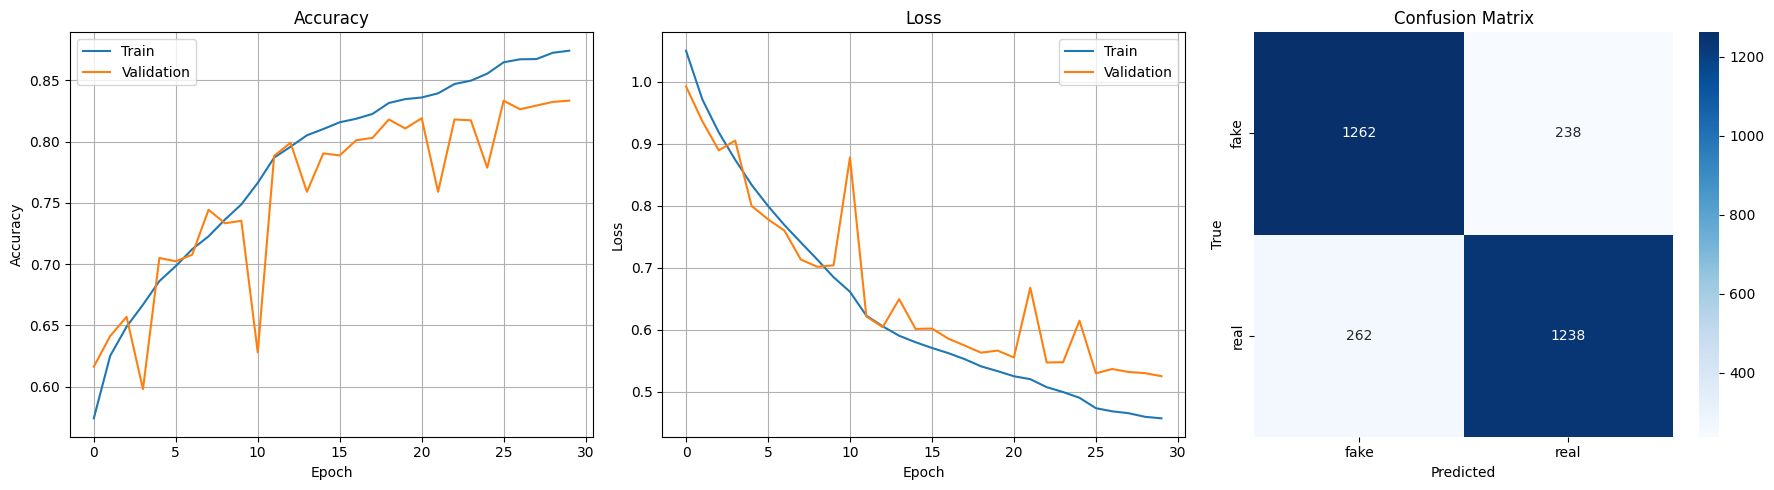

In [ ]:
# Evaluation
valid_gen.reset()

y_prob = cnn_model.predict(valid_gen)
y_pred = (y_prob > 0.5).astype(int).ravel()
y_true = valid_gen.classes

class_names = list(valid_gen.class_indices.keys())

acc = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("="*55)
print("Custom CNN - Evaluation Results")
print("="*55)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"AUC-ROC   : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

# Visualization
plt.figure(figsize=(18,5))

# Accuracy
plt.subplot(1,3,1)
plt.plot(cnn_history.history['accuracy'], label='Train')
plt.plot(cnn_history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,3,2)
plt.plot(cnn_history.history['loss'], label='Train')
plt.plot(cnn_history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Confusion Matrix
plt.subplot(1,3,3)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.tight_layout()
plt.show()

### Custom CNN V3 — Hyperband Tuning

We built a custom CNN from scratch using SeparableConv2D layers with progressive SpatialDropout across 5 convolutional blocks. Hyperparameters were tuned using Keras Tuner's Hyperband algorithm over 15 epochs. The search covered learning rates (3e-4, 1e-4, 5e-5), dropout rates (0.45, 0.55, 0.65), L2 regularization (3e-4, 6e-4, 1e-3), and label smoothing (0.05, 0.10, 0.15). The final model was trained for up to 40 epochs using a warmup + cosine decay learning rate schedule (3 warmup epochs) and EarlyStopping (patience=8).

In [ ]:
# Imports
import math, shutil
import keras_tuner as kt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, LearningRateScheduler
)
from tensorflow.keras import backend as K

In [ ]:
def make_lr_schedule(base_lr, warmup_epochs=3, total_epochs=30):
    def schedule(epoch, lr):
        if epoch < warmup_epochs:
            return base_lr / 10.0 + epoch * (base_lr * 0.9 / warmup_epochs)
        progress = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return base_lr * 0.5 * (1.0 + math.cos(math.pi * progress))
    return schedule

In [ ]:
def build_cnn_v3(hp):
    learning_rate     = hp.Choice('learning_rate',    [3e-4, 1e-4, 5e-5])
    dropout_rate      = hp.Choice('dropout',           [0.45, 0.55, 0.65])
    l2_regularization = hp.Choice('l2_reg',            [3e-4, 6e-4, 1e-3])
    label_smoothing   = hp.Choice('label_smoothing',   [0.05, 0.10, 0.15])

    def conv_block(input_tensor, filters, spatial_dropout_rate):
        conv_layer       = layers.SeparableConv2D(
                               filters, 3, padding='same', activation='relu',
                               depthwise_regularizer=regularizers.l2(l2_regularization),
                               pointwise_regularizer=regularizers.l2(l2_regularization)
                           )(input_tensor)
        batch_norm_layer = layers.BatchNormalization()(conv_layer)
        pooling_layer    = layers.MaxPooling2D(2)(batch_norm_layer)
        dropout_layer    = layers.SpatialDropout2D(spatial_dropout_rate)(pooling_layer)
        return dropout_layer

    input_layer  = layers.Input(shape=(128, 128, 3))
    first_block  = conv_block(input_layer, 32,  0.10)
    second_block = conv_block(first_block,  64,  0.15)
    third_block  = conv_block(second_block, 128, 0.20)
    fourth_block = conv_block(third_block,  96,  0.25)
    fifth_block  = conv_block(fourth_block, 64,  0.30)

    global_pooling_layer = layers.GlobalAveragePooling2D()(fifth_block)

    dense_layer_1    = layers.Dense(
                           128, activation='relu',
                           kernel_regularizer=regularizers.l2(l2_regularization)
                       )(global_pooling_layer)
    batch_norm_dense = layers.BatchNormalization()(dense_layer_1)
    dropout_dense_1  = layers.Dropout(dropout_rate)(batch_norm_dense)

    dense_layer_2   = layers.Dense(
                          32, activation='relu',
                          kernel_regularizer=regularizers.l2(l2_regularization)
                      )(dropout_dense_1)
    dropout_dense_2 = layers.Dropout(dropout_rate * 0.5)(dense_layer_2)

    output_layer = layers.Dense(1, activation='sigmoid')(dropout_dense_2)

    model = models.Model(input_layer, output_layer, name='Custom_CNN_V2')
    model.compile(
        optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
        metrics=['accuracy']
    )
    return model

In [ ]:
#  Hyperband search
shutil.rmtree('/content/hyperband_cnn_dir_v3', ignore_errors=True)

tuner = kt.Hyperband(
    build_cnn_v3,
    objective='val_accuracy',
    max_epochs=15,
    factor=3,
    directory='/content/hyperband_cnn_dir_v3',
    project_name='Custom_CNN_V2'
)
tuner.search(
    train_gen,
    validation_data=valid_gen,
    epochs=15,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Learning Rate   :", best_hps.get('learning_rate'))
print("Dropout         :", best_hps.get('dropout'))
print("L2 Reg          :", best_hps.get('l2_reg'))
print("Label Smoothing :", best_hps.get('label_smoothing'))

Trial 30 Complete [00h 04m 28s]
val_accuracy: 0.6514190435409546

Best val_accuracy So Far: 0.7275459170341492
Total elapsed time: 01h 01m 17s
Learning Rate   : 0.0003
Dropout         : 0.45
L2 Reg          : 0.001
Label Smoothing : 0.05


In [ ]:
# Final training
K.clear_session()

TOTAL_EPOCHS = 40
BASE_LR      = best_hps.get('learning_rate')

cnn3_model  = tuner.hypermodel.build(best_hps)
cnn3_model.summary()

cnn3_history = cnn3_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=TOTAL_EPOCHS,
    callbacks=[
        LearningRateScheduler(
            make_lr_schedule(BASE_LR, warmup_epochs=3, total_epochs=TOTAL_EPOCHS),
            verbose=0
        ),
        EarlyStopping(
            monitor='val_loss', patience=8,
            restore_best_weights=True, verbose=1
        ),
    ],
    verbose=1
)

Model: "Custom_CNN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 128, 128, 32)   │           155 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 64, 64, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 64, 64, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 32, 32, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 32, 32, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_2             │ (None, 16, 16, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 16, 16, 96)     │        13,536 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_3             │ (None, 8, 8, 96)       │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_4              │ (None, 8, 8, 64)       │         7,072 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 46,588 (181.98 KB)

 Trainable params: 45,564 (177.98 KB)

 Non-trainable params: 1,024 (4.00 KB)

Epoch 1/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 52s 50ms/step - accuracy: 0.5027 - loss: 1.3804 - val_accuracy: 0.4875 - val_loss: 1.1644 - learning_rate: 3.0000e-05
Epoch 2/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.5009 - loss: 1.2963 - val_accuracy: 0.5042 - val_loss: 1.1430 - learning_rate: 1.2000e-04
Epoch 3/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.5024 - loss: 1.2086 - val_accuracy: 0.5242 - val_loss: 1.1103 - learning_rate: 2.1000e-04
Epoch 4/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.5039 - loss: 1.1347 - val_accuracy: 0.5165 - val_loss: 1.0710 - learning_rate: 3.0000e-04
Epoch 5/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.5111 - loss: 1.0740 - val_accuracy: 0.5265 - val_loss: 1.0282 - learning_rate: 2.9946e-04
Epoch 6/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.5207 - loss: 1.0213 - val_accuracy: 0.5282 - val_loss: 0.9880 - learning_rate: 2.9784e-04
Epoch 7/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/ste

In [ ]:
def visualize_and_evaluate_model(model, history, generator, model_name):

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0].set_title(f'{model_name} - Accuracy', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[1].set_title(f'{model_name} - Loss', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    generator.reset()
    y_pred_prob = model.predict(generator, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    y_true = generator.classes

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    auc  = roc_auc_score(y_true, y_pred_prob)

    print(f'\n{"="*50}')
    print(f'{model_name} — Evaluation Results')
    print(f'{"="*50}')
    print(f'Accuracy  : {acc:.4f}')
    print(f'Precision : {prec:.4f}')
    print(f'Recall    : {rec:.4f}')
    print(f'F1-Score  : {f1:.4f}')
    print(f'AUC-ROC   : {auc:.4f}')

    print('\nClassification Report:')
    print(classification_report(y_true, y_pred, target_names=['Fake', 'Real']))

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Fake', 'Real'],
        yticklabels=['Fake', 'Real'],
        ax=axes[2]
    )
    axes[2].set_title(f'{model_name} - Confusion Matrix', fontweight='bold')
    axes[2].set_xlabel('Predicted Label')
    axes[2].set_ylabel('True Label')

    plt.tight_layout()
    plt.show()

    return {
        'model'    : model_name,
        'accuracy' : acc,
        'precision': prec,
        'recall'   : rec,
        'f1'       : f1,
        'auc'      : auc
    }


custom_cnn_v3 — Evaluation Results
Accuracy  : 0.7699
Precision : 0.8634
Recall    : 0.6415
F1-Score  : 0.7361
AUC-ROC   : 0.8682

Classification Report:
              precision    recall  f1-score   support

        Fake       0.71      0.90      0.80      1497
        Real       0.86      0.64      0.74      1498

    accuracy                           0.77      2995
   macro avg       0.79      0.77      0.77      2995
weighted avg       0.79      0.77      0.77      2995



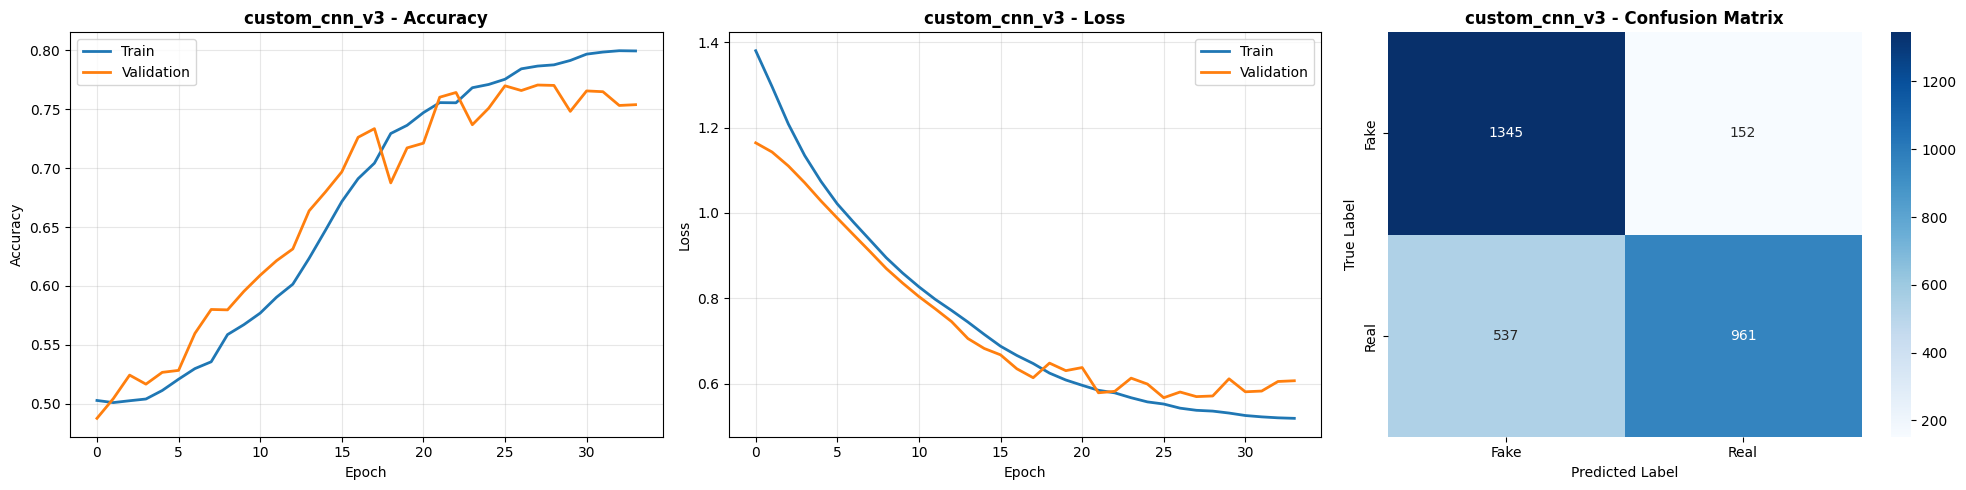

In [ ]:
cnn3_results = visualize_and_evaluate_model(
    model=cnn3_model,
    history=cnn3_history,
    generator=valid_gen,
    model_name='custom_cnn_v3'
)

In [ ]:
#  Save the model
cnn3_model.save('/content/custom_cnn_best.keras')
print("Model saved.")

Model saved.


###ResNet50 — Transfer Learning
We used ResNet50 pretrained on ImageNet as a frozen feature extractor. The base layers were kept frozen throughout training and a custom classification head was added on top. Hyperparameters were tuned using Random Search over 6 combinations, each tested for up to 8 epochs. The search covered learning rates (1e-4, 5e-5, 1e-5), dropout rates (0.3, 0.4, 0.5) and dense units (128, 256). The best configuration was selected based on highest validation accuracy with an overfitting gap below 0.08. The final model was then trained for up to 50 epochs using EarlyStopping (patience=7) and ReduceLROnPlateau (factor=0.3, patience=3).

In [ ]:
#  Import Libraries


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
# Create Generators for ResNet50
IMG_SIZE_RESNET = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

valid_datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen_resnet = train_datagen_resnet.flow_from_directory(
    AUG_TRAIN_DIR,
    target_size=IMG_SIZE_RESNET,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

valid_gen_resnet = valid_datagen_resnet.flow_from_directory(
    VALID_DIR,
    target_size=IMG_SIZE_RESNET,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print("Train images :", train_gen_resnet.samples)
print("Valid images :", valid_gen_resnet.samples)
print("Class indices:", train_gen_resnet.class_indices)

Found 21000 images belonging to 2 classes.
Found 2995 images belonging to 2 classes.
Train images : 21000
Valid images : 2995
Class indices: {'fake': 0, 'real': 1}


In [ ]:
# Build ResNet50 Model
def build_resnet_model(lr, dropout, dense_units, unfreeze_layers):
    base_model = ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze all base layers completely
    base_model.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)

    # First dense block
    x = layers.Dense(
        dense_units,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.005)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)

    # Second dense block
    x = layers.Dense(
        32,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.005)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)

    output = layers.Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=output, name='ResNet50_Tuned')

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
# Define Random Search Space
param_dist = {
    'lr'             : [1e-4, 5e-5, 1e-5],
    'dropout'        : [0.3, 0.4, 0.5],
    'dense_units'    : [128, 256],
    'unfreeze_layers': [0, 0, 10]
}

n_iter_search = 6
random_params = list(ParameterSampler(param_dist, n_iter=n_iter_search, random_state=42))

print("Randomly selected parameter combinations:")
for i, params in enumerate(random_params, 1):
    print(f"{i}. {params}")
# Run Random Search
resnet_tuning_results = []

for i, params in enumerate(random_params, 1):
    print(f'\n[{i}/{n_iter_search}] Testing: {params}')

    train_gen_resnet.reset()
    valid_gen_resnet.reset()

    model = build_resnet_model(
        lr=params['lr'],
        dropout=params['dropout'],
        dense_units=params['dense_units'],
        unfreeze_layers=params['unfreeze_layers']
    )

    history = model.fit(
        train_gen_resnet,
        validation_data=valid_gen_resnet,
        epochs=8,
        callbacks=[
            EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
        ],
        verbose=1
    )

    val_acc     = max(history.history['val_accuracy'])
    val_loss    = min(history.history['val_loss'])
    train_acc   = max(history.history['accuracy'])
    overfit_gap = round(train_acc - val_acc, 4)

    resnet_tuning_results.append({
        'lr'             : params['lr'],
        'dropout'        : params['dropout'],
        'dense_units'    : params['dense_units'],
        'unfreeze_layers': params['unfreeze_layers'],
        'val_accuracy'   : round(val_acc, 4),
        'val_loss'       : round(val_loss, 4),
        'train_accuracy' : round(train_acc, 4),
        'overfit_gap'    : overfit_gap
    })

    pd.DataFrame(resnet_tuning_results).to_csv(
        '/content/drive/MyDrive/results_resnet_random_search.csv',
        index=False
    )

    print(f"Val Acc: {val_acc:.4f} | Train Acc: {train_acc:.4f} | Gap: {overfit_gap:.4f}")

Randomly selected parameter combinations:
1. {'unfreeze_layers': 0, 'lr': 0.0001, 'dropout': 0.5, 'dense_units': 128}
2. {'unfreeze_layers': 0, 'lr': 5e-05, 'dropout': 0.5, 'dense_units': 256}
3. {'unfreeze_layers': 0, 'lr': 5e-05, 'dropout': 0.5, 'dense_units': 256}
4. {'unfreeze_layers': 0, 'lr': 5e-05, 'dropout': 0.4, 'dense_units': 128}
5. {'unfreeze_layers': 10, 'lr': 1e-05, 'dropout': 0.4, 'dense_units': 256}
6. {'unfreeze_layers': 10, 'lr': 5e-05, 'dropout': 0.3, 'dense_units': 128}

[1/6] Testing: {'unfreeze_layers': 0, 'lr': 0.0001, 'dropout': 0.5, 'dense_units': 128}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/8
657/657 ━━━━━━━━━━━━━━━━━━━━ 63s 73ms/step - accuracy: 0.6330 - loss: 2.1003 - val_accuracy: 0.7162 - val_loss: 1.8410 - learning_rate: 1.0000e-04
Epoch 2/8
657/657 ━━━━━━━━━━━━━━━━━━━━ 32s 49ms/step - accuracy: 0.6955 - loss: 1.7864 - val_accuracy: 0.7272 - val_loss: 1.6568 - learning_rate: 1.0000e-04
Epoch 3/8
657/657 ━━━━━━━━━━━━━━━━━━━━ 32s 48ms/ste

In [ ]:
# Show Random Search Results and Select Best Parameters
resnet_tuning_df = pd.DataFrame(resnet_tuning_results).sort_values(
    'val_accuracy', ascending=False
).reset_index(drop=True)

print("\n--------- ResNet50 Random Search Results -----------")
print(resnet_tuning_df.to_string(index=False))

# Keep only models with acceptable overfit gap, then sort by val_accuracy
good_models = resnet_tuning_df[resnet_tuning_df['overfit_gap'] < 0.08].sort_values(
    'val_accuracy', ascending=False
).reset_index(drop=True)

# Fallback: if all models overfit, pick the one with lowest gap
if good_models.empty:
    good_models = resnet_tuning_df.sort_values('overfit_gap', ascending=True).reset_index(drop=True)
    print("All models show overfitting - selecting the one with lowest gap")

best_resnet_params = good_models.iloc[0]

best_lr              = best_resnet_params['lr']
best_dropout         = best_resnet_params['dropout']
best_dense_units     = int(best_resnet_params['dense_units'])
best_unfreeze_layers = int(best_resnet_params['unfreeze_layers'])

print("\nBest ResNet50 Parameters:")
print("Learning Rate   :", best_lr)
print("Dropout         :", best_dropout)
print("Dense Units     :", best_dense_units)
print("Unfreeze Layers :", best_unfreeze_layers)
print("Best Val Acc    :", best_resnet_params['val_accuracy'])
print("Overfit Gap     :", best_resnet_params['overfit_gap'])


--------- ResNet50 Random Search Results -----------
     lr  dropout  dense_units  unfreeze_layers  val_accuracy  val_loss  train_accuracy  overfit_gap
0.00010      0.5          128                0        0.7589    0.9279          0.8024       0.0435
0.00005      0.5          256                0        0.7509    1.7421          0.7745       0.0236
0.00005      0.5          256                0        0.7436    1.6653          0.7739       0.0303
0.00005      0.3          128               10        0.7432    1.3629          0.7748       0.0316
0.00005      0.4          128                0        0.7419    1.3338          0.7712       0.0293
0.00001      0.4          256               10        0.6835    2.8976          0.6900       0.0066

Best ResNet50 Parameters:
Learning Rate   : 0.0001
Dropout         : 0.5
Dense Units     : 128
Unfreeze Layers : 0
Best Val Acc    : 0.7589
Overfit Gap     : 0.0435


In [ ]:
# build with best params
resnet_model = build_resnet_model(
    lr=best_lr,
    dropout=best_dropout,
    dense_units=best_dense_units,
    unfreeze_layers=0
)

resnet_callbacks = [
    EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-7),
]

resnet_history = resnet_model.fit(
    train_gen_resnet,
    validation_data=valid_gen_resnet,
    epochs=50,
    callbacks=resnet_callbacks,
    verbose=1
)

Epoch 1/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 58s 69ms/step - accuracy: 0.6325 - loss: 2.1419 - val_accuracy: 0.6825 - val_loss: 1.8771 - learning_rate: 1.0000e-04
Epoch 2/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 34s 52ms/step - accuracy: 0.6798 - loss: 1.8487 - val_accuracy: 0.6858 - val_loss: 1.7159 - learning_rate: 1.0000e-04
Epoch 3/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 33s 51ms/step - accuracy: 0.7095 - loss: 1.6296 - val_accuracy: 0.6765 - val_loss: 1.6100 - learning_rate: 1.0000e-04
Epoch 4/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 33s 51ms/step - accuracy: 0.7340 - loss: 1.4380 - val_accuracy: 0.7389 - val_loss: 1.3627 - learning_rate: 1.0000e-04
Epoch 5/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 34s 51ms/step - accuracy: 0.7512 - loss: 1.2823 - val_accuracy: 0.7102 - val_loss: 1.3011 - learning_rate: 1.0000e-04
Epoch 6/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 36s 55ms/step - accuracy: 0.7652 - loss: 1.1486 - val_accuracy: 0.7389 - val_loss: 1.1616 - learning_rate: 1.0000e-04
Epoch 7/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 37s 56ms/ste


--------------------------------------------------
ResNet50 — Evaluation Results
--------------------------------------------------
Accuracy  : 0.8184
Precision : 0.8159
Recall    : 0.8224
F1-Score  : 0.8191
AUC-ROC   : 0.8966

Classification Report:
              precision    recall  f1-score   support

        Fake       0.82      0.81      0.82      1497
        Real       0.82      0.82      0.82      1498

    accuracy                           0.82      2995
   macro avg       0.82      0.82      0.82      2995
weighted avg       0.82      0.82      0.82      2995



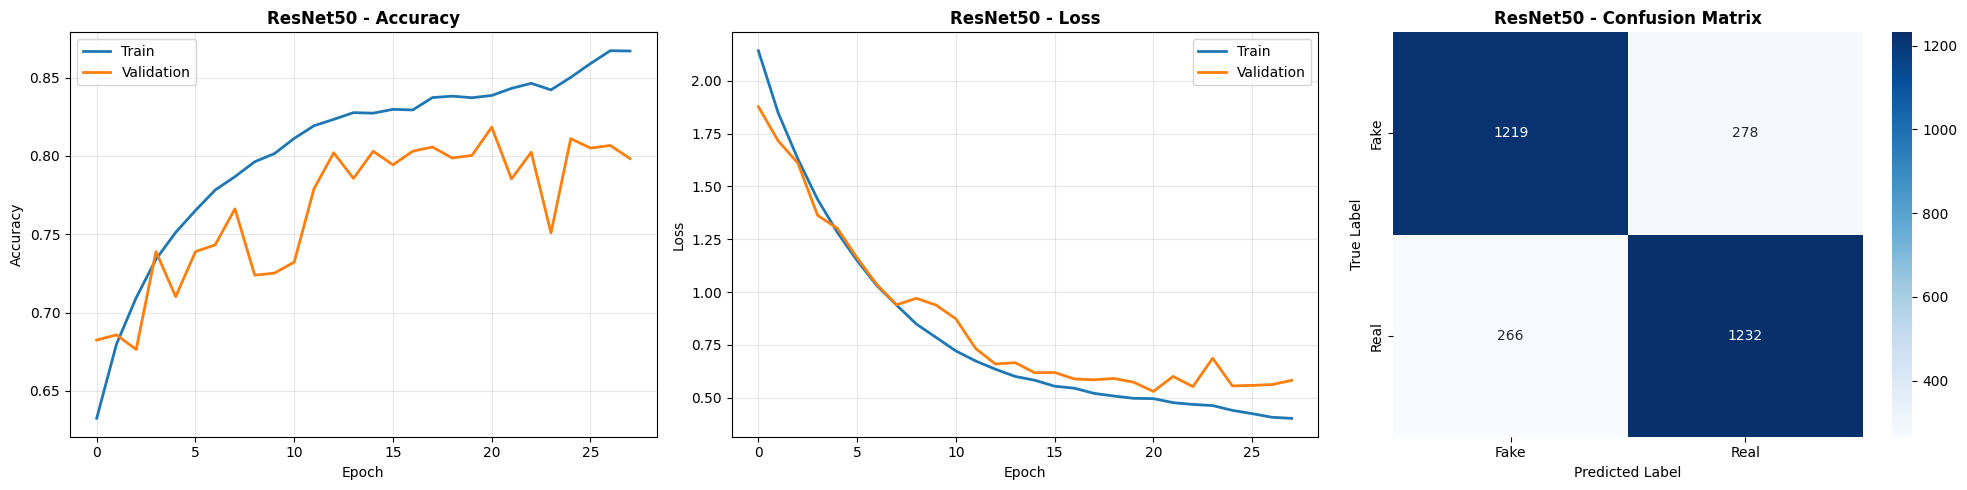

In [ ]:
# Visualize and Evaluate ResNet50 Model

def visualize_and_evaluate_model(model, history, generator, model_name):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0].set_title(f'{model_name} - Accuracy', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[1].set_title(f'{model_name} - Loss', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Predictions
    generator.reset()
    y_pred_prob = model.predict(generator, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    y_true = generator.classes

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_pred_prob)

    print(f'\n{"-"*50}')
    print(f'{model_name} — Evaluation Results')
    print(f'{"-"*50}')
    print(f'Accuracy  : {acc:.4f}')
    print(f'Precision : {prec:.4f}')
    print(f'Recall    : {rec:.4f}')
    print(f'F1-Score  : {f1:.4f}')
    print(f'AUC-ROC   : {auc:.4f}')

    print('\nClassification Report:')
    print(classification_report(y_true, y_pred, target_names=['Fake', 'Real']))

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Fake', 'Real'],
        yticklabels=['Fake', 'Real'],
        ax=axes[2]
    )
    axes[2].set_title(f'{model_name} - Confusion Matrix', fontweight='bold')
    axes[2].set_xlabel('Predicted Label')
    axes[2].set_ylabel('True Label')

    plt.tight_layout()
    plt.show()

    return {
        'model': model_name,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'auc': auc
    }

resnet_results = visualize_and_evaluate_model(
    model=resnet_model,
    history=resnet_history,
    generator=valid_gen_resnet,
    model_name='ResNet50'
)

In [ ]:
resnet_model.save('/content/best_resnet50.keras')
print("Model saved.")

Model saved.


###EfficientNetB0 — Transfer Learning

We used EfficientNetB0 pretrained on ImageNet as a frozen feature extractor with the same classification head structure as ResNet50. Hyperparameters were tuned using Random Search over 6 combinations, each tested for up to 8 epochs, using the same search space as ResNet50 (learning rate, dropout, dense units, unfrozen layers). The final model was trained for up to 50 epochs using EarlyStopping (patience=5) and ReduceLROnPlateau (factor=0.3, patience=2).


In [ ]:
#Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import layers, regularizers
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
# Create Generators for EfficientNet
IMG_SIZE_EFF = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_datagen_eff = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

valid_datagen_eff = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen_eff = train_datagen_eff.flow_from_directory(
    AUG_TRAIN_DIR,
    target_size=IMG_SIZE_EFF,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

valid_gen_eff = valid_datagen_eff.flow_from_directory(
    VALID_DIR,
    target_size=IMG_SIZE_EFF,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print("Train images:", train_gen_eff.samples)
print("Valid images:", valid_gen_eff.samples)

Found 21072 images belonging to 2 classes.
Found 3000 images belonging to 2 classes.
Train images: 21072
Valid images: 3000


In [ ]:
# Build EfficientNetB0
def build_efficientnet_model(lr, dropout, dense_units, unfreeze_layers):
    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze all base layers
    base_model.trainable = False

    if unfreeze_layers > 0:
        for layer in base_model.layers[-unfreeze_layers:]:
            layer.trainable = True

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)

    # First dense block
    x = layers.Dense(
        dense_units,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.005)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)

    # Second dense block
    x = layers.Dense(
        32,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.005)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)

    output = layers.Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=output, name='EfficientNetB0_Tuned')

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
# Define Random Search Space
param_dist_eff = {
    'lr'             : [1e-4, 5e-5, 1e-5],
    'dropout'        : [0.3, 0.4, 0.5],
    'dense_units'    : [128, 256],
    'unfreeze_layers': [0, 0, 10]
}

n_iter_search_eff = 6
random_params_eff = list(
    ParameterSampler(param_dist_eff, n_iter=n_iter_search_eff, random_state=42)
)

for i, params in enumerate(random_params_eff, 1):
    print(f"{i}. {params}")
# Run Random Search with overfit gap tracking
eff_tuning_results = []

for i, params in enumerate(random_params_eff, 1):
    print(f'\n[{i}/{n_iter_search_eff}] Testing: {params}')

    train_gen_eff.reset()
    valid_gen_eff.reset()

    model = build_efficientnet_model(
        lr=params['lr'],
        dropout=params['dropout'],
        dense_units=params['dense_units'],
        unfreeze_layers=params['unfreeze_layers']
    )

    history = model.fit(
        train_gen_eff,
        validation_data=valid_gen_eff,
        epochs=8,
        callbacks=[
            EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
        ],
        verbose=1
    )

    val_acc     = max(history.history['val_accuracy'])
    val_loss    = min(history.history['val_loss'])
    train_acc   = max(history.history['accuracy'])
    overfit_gap = round(train_acc - val_acc, 4)

    eff_tuning_results.append({
        'lr'             : params['lr'],
        'dropout'        : params['dropout'],
        'dense_units'    : params['dense_units'],
        'unfreeze_layers': params['unfreeze_layers'],
        'val_accuracy'   : round(val_acc, 4),
        'val_loss'       : round(val_loss, 4),
        'train_accuracy' : round(train_acc, 4),
        'overfit_gap'    : overfit_gap
    })

    pd.DataFrame(eff_tuning_results).to_csv(
        '/content/drive/MyDrive/results_efficientnet.csv',
        index=False
    )

    print(f"Val Acc: {val_acc:.4f} | Train Acc: {train_acc:.4f} | Gap: {overfit_gap:.4f}")


# Show results and select best parameters
eff_df = pd.DataFrame(eff_tuning_results).sort_values(
    'val_accuracy', ascending=False
).reset_index(drop=True)

print("\n--------- EfficientNetB0 Random Search Results -----------")
print(eff_df.to_string(index=False))

# Keep only models with acceptable overfit gap
good_models = eff_df[eff_df['overfit_gap'] < 0.08].sort_values(
    'val_accuracy', ascending=False
).reset_index(drop=True)

# Fallback: if all models overfit, pick lowest gap
if good_models.empty:
    good_models = eff_df.sort_values('overfit_gap', ascending=True).reset_index(drop=True)
    print("All models show overfitting - selecting the one with lowest gap")

best_eff     = good_models.iloc[0]
best_lr      = best_eff['lr']
best_dropout = best_eff['dropout']
best_dense   = int(best_eff['dense_units'])
best_unfreeze = int(best_eff['unfreeze_layers'])

print(f"\nBest Learning Rate   : {best_lr}")
print(f"Best Dropout         : {best_dropout}")
print(f"Best Dense Units     : {best_dense}")
print(f"Best Unfreeze Layers : {best_unfreeze}")
print(f"Best Val Accuracy    : {best_eff['val_accuracy']}")
print(f"Overfit Gap          : {best_eff['overfit_gap']}")

1. {'unfreeze_layers': 0, 'lr': 0.0001, 'dropout': 0.5, 'dense_units': 128}
2. {'unfreeze_layers': 0, 'lr': 5e-05, 'dropout': 0.5, 'dense_units': 256}
3. {'unfreeze_layers': 0, 'lr': 5e-05, 'dropout': 0.5, 'dense_units': 256}
4. {'unfreeze_layers': 0, 'lr': 5e-05, 'dropout': 0.4, 'dense_units': 128}
5. {'unfreeze_layers': 10, 'lr': 1e-05, 'dropout': 0.4, 'dense_units': 256}
6. {'unfreeze_layers': 10, 'lr': 5e-05, 'dropout': 0.3, 'dense_units': 128}

[1/6] Testing: {'unfreeze_layers': 0, 'lr': 0.0001, 'dropout': 0.5, 'dense_units': 128}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8
659/659 ━━━━━━━━━━━━━━━━━━━━ 87s 87ms/step - accuracy: 0.6138 - loss: 2.1229 - val_accuracy: 0.6983 - val_loss: 1.8581 - learning_rate: 1.0000e-04
Epoch 2/8
659/659 ━━━━━━━━━━━━━━━━━━━━ 22s 34ms/step - accuracy: 0.6721 - loss: 1.8712 - val_accuracy: 0.7253 - val_loss: 1.6800 - learning_rate: 1.0000e-04
Epoch 3/8
659/659 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.6964 - loss: 1.6701 - val_

In [ ]:
# build EfficientNetB0
eff_model = build_efficientnet_model(
    lr=best_lr,
    dropout=best_dropout,
    dense_units=best_dense,
    unfreeze_layers=0
)

# Train
eff_history = eff_model.fit(
    train_gen_eff,
    validation_data=valid_gen_eff,
    epochs=50,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=2,
            min_lr=1e-7
        )
    ],
    verbose=1
)

Epoch 1/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 67s 69ms/step - accuracy: 0.5856 - loss: 2.1878 - val_accuracy: 0.6673 - val_loss: 1.9591 - learning_rate: 5.0000e-05
Epoch 2/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 23s 35ms/step - accuracy: 0.6518 - loss: 1.9945 - val_accuracy: 0.6953 - val_loss: 1.8381 - learning_rate: 5.0000e-05
Epoch 3/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - accuracy: 0.6822 - loss: 1.8606 - val_accuracy: 0.7077 - val_loss: 1.7348 - learning_rate: 5.0000e-05
Epoch 4/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.6941 - loss: 1.7559 - val_accuracy: 0.7283 - val_loss: 1.6400 - learning_rate: 5.0000e-05
Epoch 5/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - accuracy: 0.7140 - loss: 1.6469 - val_accuracy: 0.7477 - val_loss: 1.5476 - learning_rate: 5.0000e-05
Epoch 6/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.7248 - loss: 1.5549 - val_accuracy: 0.7490 - val_loss: 1.4800 - learning_rate: 5.0000e-05
Epoch 7/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/ste


--------------------------------------------------
EfficientNetB0 — Evaluation Results
--------------------------------------------------
Accuracy  : 0.7727
Precision : 0.7756
Recall    : 0.7673
F1-Score  : 0.7714
AUC-ROC   : 0.8543

Classification Report:
              precision    recall  f1-score   support

        Fake       0.77      0.78      0.77      1500
        Real       0.78      0.77      0.77      1500

    accuracy                           0.77      3000
   macro avg       0.77      0.77      0.77      3000
weighted avg       0.77      0.77      0.77      3000



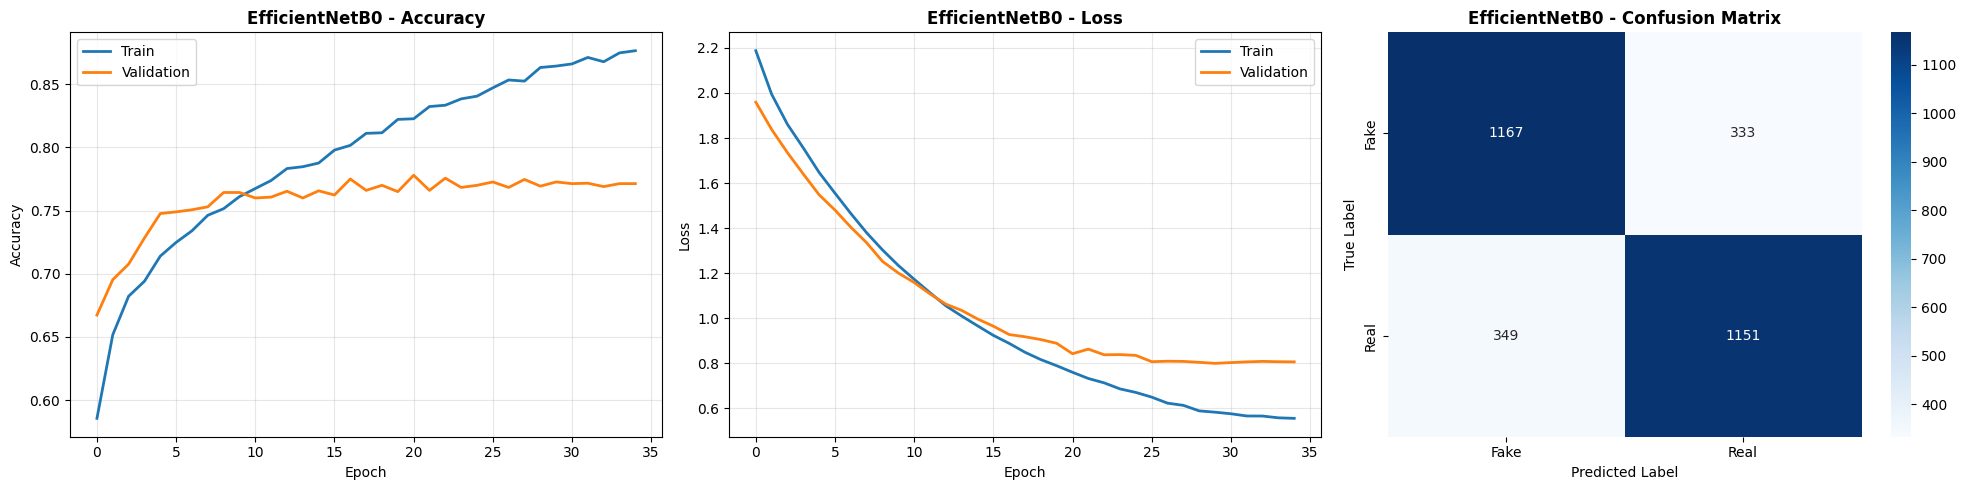

In [ ]:
#Evaluation
eff_results = visualize_and_evaluate_model(
    model=eff_model,
    history=eff_history,
    generator=valid_gen_eff,
    model_name='EfficientNetB0'
)